# Seed label values: rebuild check and first look

The 8 seed brands are the only analogs with label reads (line of therapy, dosing, launch date, # competitors). 27 of their 31 values are approved (`data/reference/analog_evidence.csv`). This notebook:

1. **Checks the rebuild:** after `python -m pipeline.build`, every approved value should appear in `analog_features.csv`, and only the unapproved ones should be missing. Run it after rebuilding; the check cell says whether the tables match.
2. **Takes a first look** at whether the label fields line up with uptake among the seed brands. Eight drugs is far too few to test anything; this only shows what the analog-matching test will look like once more labels are read.

The analysis in part 2 reads approved values straight from `analog_evidence.csv`, so it works before and after the rebuild.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
REFERENCE = ROOT / "data" / "reference"
pd.set_option("display.max_colwidth", 70)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
FIELDS = ["line_of_therapy", "dosing_frequency", "launch_date", "n_competitors_at_launch"]

ev = pd.read_csv(REFERENCE / "analog_evidence.csv", dtype=str, keep_default_na=False)
ev["approved"] = ev.approved.str.lower() == "true"
features = pd.read_csv(PROCESSED / "analog_features.csv")
curves = pd.read_csv(PROCESSED / "launch_curves.csv")
fits = pd.read_csv(PROCESSED / "bass_fits.csv")
SEED = list(ev.analog_id.unique())
print(f"{len(ev)} values for {len(SEED)} analogs: {ev.approved.sum()} approved, {(~ev.approved).sum()} waiting")

31 values for 8 analogs: 27 approved, 4 waiting


## Review status

Each value with ✓ if approved, ⧗ if waiting for review; blank = no value yet.

In [2]:
status = ev.assign(cell=ev.value + ev.approved.map({True: "  ✓", False: "  ⧗"}))
status.pivot(index="analog_id", columns="field", values="cell").reindex(index=SEED, columns=FIELDS).fillna("")

field,line_of_therapy,dosing_frequency,launch_date,n_competitors_at_launch
analog_id,,,,
otezla_oral,no prior therapy required ✓,twice daily (after 5-day titration) ✓,2014-03 ⧗,6 ✓
cosentyx_sc,no prior therapy required (systemic or phototherapy candidates) ✓,"every 4 weeks (weekly loading, weeks 0-4) ✓",,5 ✓
taltz_sc,no prior therapy required (systemic or phototherapy candidates) ✓,every 4 weeks (every 2 weeks to week 12) ✓,2016-04 ✓,6 ✓
siliq_sc,after other systemic therapy ✓,"every 2 weeks (weekly loading, weeks 0-2) ✓",2017-07-27 ✓,8 ✓
tremfya_sc,no prior therapy required (systemic or phototherapy candidates) ✓,every 8 weeks (after weeks 0 and 4) ✓,2017-07 ⧗,8 ✓
skyrizi_sc,no prior therapy required (systemic or phototherapy candidates) ✓,every 12 weeks (after weeks 0 and 4) ✓,2019-05 ⧗,11 ✓
sotyktu_oral,no prior therapy required (systemic or phototherapy candidates) ✓,once daily ✓,2022-09 ⧗,12 ✓
ibrance_oral,1L metastatic (initial endocrine-based therapy) ✓,"once daily, 21 days on / 7 days off ✓",2015-02-03 ✓,0 ✓


## 1. Rebuild check

What the rebuild should produce, compared with what's in `data/processed/` now:
- `analog_features` has each **approved** line of therapy, dosing frequency and # competitors, and blanks for unapproved ones.
- `fields_not_approved` counts each analog's unapproved values.
- Analogs with an approved launch date have `launch_source = evidence`, and their launch quarter is that date's quarter.

In [3]:
def quarter(d):
    return f"{d[:4]}Q{(int(d[5:7]) - 1) // 3 + 1}"


f = features.set_index("analog_id")
approved = ev[ev.approved].pivot(index="analog_id", columns="field", values="value")
rows = []
for a in SEED:
    for field in ["line_of_therapy", "dosing_frequency", "n_competitors_at_launch"]:
        want = approved.at[a, field] if a in approved.index and field in approved and pd.notna(approved.at[a, field]) else ""
        have = f.at[a, field]
        have = "" if pd.isna(have) else (str(int(have)) if isinstance(have, float) else str(have))
        rows.append((a, field, want, have))
    rows.append((a, "fields_not_approved", str(int((~ev[ev.analog_id == a].approved).sum())), str(int(f.at[a, "fields_not_approved"]))))
    if a in approved.index and pd.notna(approved.loc[a].get("launch_date")):
        rows.append((a, "launch_source", "evidence", f.at[a, "launch_source"]))
        rows.append((a, "launch_quarter", quarter(approved.at[a, "launch_date"]), f.at[a, "launch_quarter"]))
check = pd.DataFrame(rows, columns=["analog_id", "check", "expected", "in analog_features"])
check["ok"] = check.expected == check["in analog_features"]

if check.ok.all():
    print(f"REBUILT: all {len(check)} checks pass; analog_features matches analog_evidence.csv")
else:
    print(f"NOT REBUILT YET: {(~check.ok).sum()} of {len(check)} checks differ. "
          "Run `python -m pipeline.build`, then re-run this notebook.")
check[~check.ok].reset_index(drop=True)

REBUILT: all 38 checks pass; analog_features matches analog_evidence.csv


,analog_id,check,expected,in analog_features,ok


## 2. First look: label fields vs uptake

Uptake measures from the committed curves and fits: quarter the curve first reaches 50% of its Q0–Q20 peak, share of peak at Q12 (year 3), whether it's still at its peak at the end of the window, and the Bass p and q. Label fields are the approved values.

Sotyktu launched in 2022 and has only 12 complete quarters, so its "peak" is the peak so far and its share-of-peak figures are inflated against the others'.

In [4]:
wide = ev[ev.approved].pivot(index="analog_id", columns="field", values="value").reindex(SEED)
c = curves[curves.analog_id.isin(SEED)]
q50 = c[c.share_of_peak >= 0.5].groupby("analog_id").q_since_launch.min()
s12 = c[c.q_since_launch == 12].set_index("analog_id").share_of_peak

uptake = pd.DataFrame({
    "line of therapy": wide.line_of_therapy,
    "dosing": wide.dosing_frequency,
    "# competitors": pd.to_numeric(wide.n_competitors_at_launch),
    "Q to 50% of peak": q50,
    "share of peak at Q12": s12.round(2),
    "still at peak at end of data": f.loc[SEED, "peak_at_last_quarter"],
    "Bass p": fits.set_index("analog_id").p.reindex(SEED).round(3),
    "Bass q": fits.set_index("analog_id").q.reindex(SEED).round(3),
    "weak fit": fits.set_index("analog_id").weak_fit_flag.reindex(SEED),
}).sort_values("# competitors")
uptake

,line of therapy,dosing,# competitors,Q to 50% of peak,share of peak at Q12,still at peak at end of data,Bass p,Bass q,weak fit
analog_id,,,,,,,,,
ibrance_oral,1L metastatic (initial endocrine-based therapy),"once daily, 21 days on / 7 days off",0,5,0.92,False,0.049,0.296,False
cosentyx_sc,no prior therapy required (systemic or phototherapy candidates),"every 4 weeks (weekly loading, weeks 0-4)",5,13,0.45,True,0.008,0.145,False
otezla_oral,no prior therapy required,twice daily (after 5-day titration),6,7,0.78,True,0.029,0.288,False
taltz_sc,no prior therapy required (systemic or phototherapy candidates),every 4 weeks (every 2 weeks to week 12),6,17,0.32,True,0.002,0.129,True
siliq_sc,after other systemic therapy,"every 2 weeks (weekly loading, weeks 0-2)",8,5,0.94,False,0.016,0.684,False
tremfya_sc,no prior therapy required (systemic or phototherapy candidates),every 8 weeks (after weeks 0 and 4),8,15,0.34,True,0.003,0.112,True
skyrizi_sc,no prior therapy required (systemic or phototherapy candidates),every 12 weeks (after weeks 0 and 4),11,12,0.50,False,0.007,0.242,False
sotyktu_oral,no prior therapy required (systemic or phototherapy candidates),once daily,12,3,0.92,True,0.129,0.242,False


Curves grouped by what the labels say. The plaque psoriasis brands with no prior therapy required are one group; Siliq (psoriasis, only after other systemic therapy), Otezla (psoriatic arthritis first) and Ibrance (1L metastatic breast cancer) each stand alone.

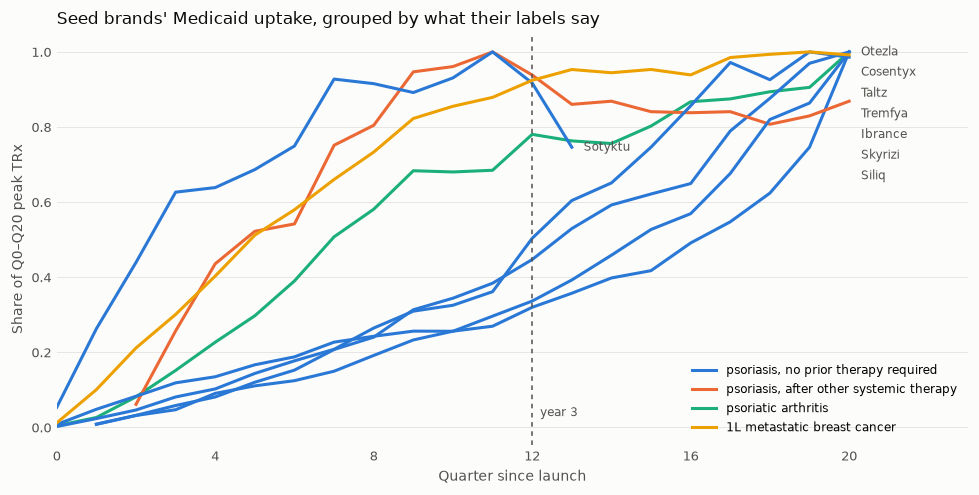

In [5]:
GROUP = {"cosentyx_sc": "psoriasis, no prior therapy required", "taltz_sc": "psoriasis, no prior therapy required",
         "tremfya_sc": "psoriasis, no prior therapy required", "skyrizi_sc": "psoriasis, no prior therapy required",
         "sotyktu_oral": "psoriasis, no prior therapy required", "siliq_sc": "psoriasis, after other systemic therapy",
         "otezla_oral": "psoriatic arthritis", "ibrance_oral": "1L metastatic breast cancer"}
COLORS = {"psoriasis, no prior therapy required": "#2a78d6", "psoriasis, after other systemic therapy": "#eb6834",
          "psoriatic arthritis": "#1baf7a", "1L metastatic breast cancer": "#eda100"}  # validated categorical slots 1-4

fig, ax = plt.subplots(figsize=(9, 4.6), dpi=110)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
ends = []
for a in SEED:
    d = c[c.analog_id == a].sort_values("q_since_launch")
    ax.plot(d.q_since_launch, d.share_of_peak, color=COLORS[GROUP[a]], linewidth=2)
    last = d.dropna(subset=["share_of_peak"]).iloc[-1]
    ends.append([last.q_since_launch, last.share_of_peak, a.split("_")[0].title()])
# spread end labels that would overlap (same end quarter, close values)
ends.sort(key=lambda e: (e[0], -e[1]))
for i in range(1, len(ends)):
    if ends[i][0] == ends[i - 1][0] and ends[i - 1][1] - ends[i][1] < 0.055:
        ends[i][1] = ends[i - 1][1] - 0.055
for x, y, name in ends:
    ax.text(x + 0.3, y, name, va="center", fontsize=8, color=INK2)
handles = [plt.Line2D([0], [0], color=col, linewidth=2) for col in COLORS.values()]
ax.legend(handles, list(COLORS), frameon=False, fontsize=8, loc="lower right")
ax.axvline(12, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(12.2, 0.03, "year 3", fontsize=8, color=INK2)
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 21, 4))
ax.set_xlabel("Quarter since launch", color=INK2, fontsize=9)
ax.set_ylabel("Share of Q0–Q20 peak TRx", color=INK2, fontsize=9)
ax.set_title("Seed brands' Medicaid uptake, grouped by what their labels say", loc="left", fontsize=11, color=INK)
ax.tick_params(colors=INK2, labelsize=8.5, length=0)
ax.grid(axis="y", color=GRID, linewidth=0.6)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
plt.show()

## Takeaways

*Eight drugs, descriptive only. These show what the matching test will look like, not whether it works.*

- **Line of therapy separates Siliq**, the only "after other systemic therapy" psoriasis drug: it reached half its peak by Q5 and peaked at Q11, while the first-line psoriasis biologics (Cosentyx, Taltz, Tremfya, Skyrizi) took 12–17 quarters and were still climbing at Q20. But Siliq is also tiny in Medicaid and carries a boxed warning, so line of therapy isn't the only difference.
- **# competitors doesn't order uptake among the psoriasis biologics:** Cosentyx (5 competitors), Taltz (6), Tremfya (8) and Skyrizi (11) all have similar slow curves. If competition matters, it isn't visible at this size.
- **Route/dosing may matter more:** the orals (Otezla, Sotyktu) reach half their peak much faster than the injectable biologics, but Sotyktu's short window inflates its numbers, and Otezla's first indication is psoriatic arthritis, not psoriasis.
- **Ibrance** (oncology) rises fast and flattens, the pattern the EDA saw for oncology generally.
- **What this means for the test:** with more label reads in one area, compare curves within groups that share line of therapy (and route), and check whether that beats the class grouping in `analog_similarity`. The seed brands are too few and too alike (6 of 8 are psoriasis) to say more.